In [37]:
import os
os.getcwd()

'C:\\Users\\DELL'

In [38]:
import pandas as pd

In [39]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [40]:
import pandas as pd

In [41]:
import pandas as pd
print(pd.__version__)

3.0.6


In [42]:
df = pd.read_csv("compressor_C101_synthetic_6months.csv")
df.head()

,timestamp,suction_pressure_bar,discharge_pressure_bar,suction_temperature_C,discharge_temperature_C,gas_flow_ksm3h,compressor_speed_rpm,power_MW,DE_vibration_mm_s,NDE_vibration_mm_s,DE_bearing_temperature_C,NDE_bearing_temperature_C,ambient_temperature_C
0,2026-03-30 00:00:00,44.6779,129.7329,34.0523,110.9809,646.7886,9642.0216,21.1941,2.6541,2.4818,70.5886,67.1222,27.6786
1,2026-03-30 01:00:00,45.0922,131.6071,32.7750,111.6735,648.4219,9650.2256,20.8158,2.6266,2.4140,71.3632,67.9501,28.3410
2,2026-03-30 02:00:00,44.4212,127.7611,33.5247,113.2364,646.2243,9646.2443,21.2927,2.5656,2.2160,70.4911,68.6081,29.3702
3,2026-03-30 03:00:00,45.1936,128.7454,34.5096,112.8171,664.5025,9671.8312,21.6641,2.6997,2.2035,70.4985,68.0562,28.4966
4,2026-03-30 04:00:00,44.7682,129.3371,35.8461,115.4765,625.4349,9649.7105,21.1288,2.8194,2.1902,70.1609,68.4848,30.0533


In [43]:
df.shape

(4320, 13)

In [44]:
df["pressure_ratio"] = df["discharge_pressure_bar"] / df["suction_pressure_bar"]

df["temperature_rise_C"] = (
    df["discharge_temperature_C"] - df["suction_temperature_C"]
)

df["power_per_flow"] = (
    df["power_MW"] / df["gas_flow_ksm3h"]
)

In [45]:
df[
    [
        "pressure_ratio",
        "temperature_rise_C",
        "power_per_flow"
    ]
].head()

,pressure_ratio,temperature_rise_C,power_per_flow
0,2.903738,76.9286,0.032768
1,2.918622,78.8985,0.032102
2,2.876129,79.7117,0.032949
3,2.848753,78.3075,0.032602
4,2.889040,79.6304,0.033783


In [46]:
features = [
    "suction_pressure_bar",
    "discharge_pressure_bar",
    "suction_temperature_C",
    "discharge_temperature_C",
    "gas_flow_ksm3h",
    "compressor_speed_rpm",
    "power_MW",
    "DE_vibration_mm_s",
    "NDE_vibration_mm_s",
    "DE_bearing_temperature_C",
    "NDE_bearing_temperature_C",
    "pressure_ratio",
    "temperature_rise_C",
    "power_per_flow"
]

In [47]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [48]:
train_end = df["timestamp"].min() + pd.Timedelta(days=120)

train = df[df["timestamp"] < train_end].copy()
test = df[df["timestamp"] >= train_end].copy()

X_train = train[features]
X_test = test[features]

In [49]:
print("Training rows:", X_train.shape)
print("Test rows:", X_test.shape)

Training rows: (2880, 14)
Test rows: (1440, 14)


In [50]:
from sklearn.preprocessing import StandardScaler

In [51]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [52]:
from sklearn.preprocessing import StandardScaler

In [53]:
from sklearn.preprocessing import StandardScaler

In [54]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [55]:
import pandas as pd

df = pd.read_csv("compressor_C101_synthetic_6months.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [56]:
df["pressure_ratio"] = df["discharge_pressure_bar"] / df["suction_pressure_bar"]
df["temperature_rise_C"] = df["discharge_temperature_C"] - df["suction_temperature_C"]
df["power_per_flow"] = df["power_MW"] / df["gas_flow_ksm3h"]

In [57]:
from sklearn.preprocessing import StandardScaler

In [58]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [59]:
features = [
    "suction_pressure_bar",
    "discharge_pressure_bar",
    "suction_temperature_C",
    "discharge_temperature_C",
    "gas_flow_ksm3h",
    "compressor_speed_rpm",
    "power_MW",
    "DE_vibration_mm_s",
    "NDE_vibration_mm_s",
    "DE_bearing_temperature_C",
    "NDE_bearing_temperature_C",
    "pressure_ratio",
    "temperature_rise_C",
    "power_per_flow"
]

train_end = df["timestamp"].min() + pd.Timedelta(days=120)

train = df[df["timestamp"] < train_end].copy()
test = df[df["timestamp"] >= train_end].copy()

X_train = train[features]
X_test = test[features]

print(X_train.shape)
print(X_test.shape)

(2880, 14)
(1440, 14)


In [60]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [61]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [62]:
from sklearn.ensemble import IsolationForest

In [63]:
model = IsolationForest(
    n_estimators=300,
    contamination=0.01,
    random_state=42
)

In [64]:
model.fit(X_train_scaled)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",300
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.01
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [65]:
test["anomaly_score_raw"] = -model.decision_function(X_test_scaled)

In [66]:
test[["timestamp", "anomaly_score_raw"]].head()

,timestamp,anomaly_score_raw
2880,2026-07-28 00:00:00,-0.071851
2881,2026-07-28 01:00:00,-0.118139
2882,2026-07-28 02:00:00,-0.084161
2883,2026-07-28 03:00:00,-0.100823
2884,2026-07-28 04:00:00,-0.094753


In [67]:
test["anomaly_score_24h"] = (
    test["anomaly_score_raw"]
    .rolling(24, min_periods=1)
    .mean()
)

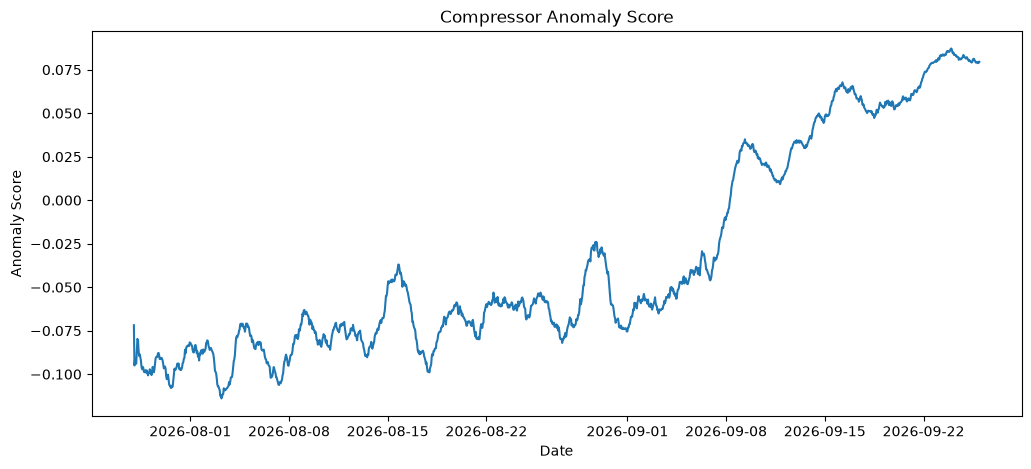

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(
    test["timestamp"],
    test["anomaly_score_24h"]
)

plt.title("Compressor Anomaly Score")
plt.xlabel("Date")
plt.ylabel("Anomaly Score")
plt.show()

In [69]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [70]:
import pandas as pd
import matplotlib.pyplot as plt

In [71]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


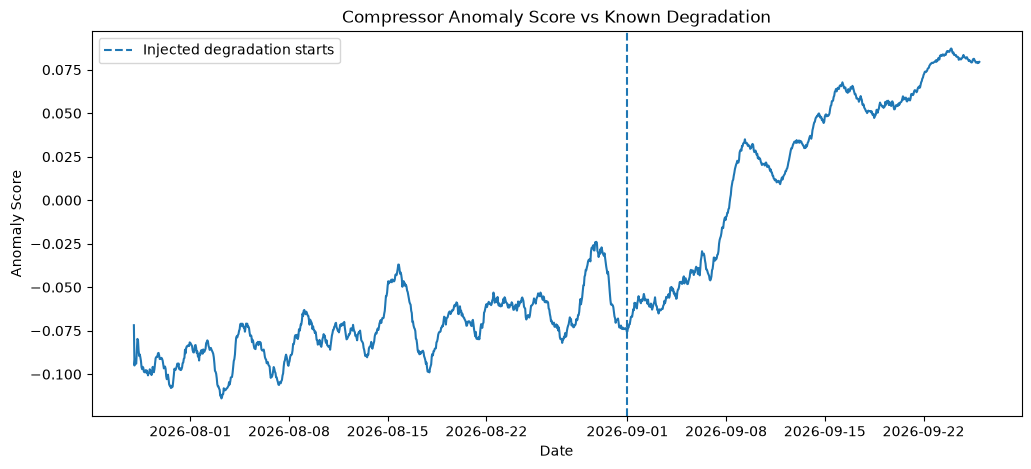

In [72]:
degradation_start = pd.Timestamp("2026-09-01")

plt.figure(figsize=(12,5))

plt.plot(
    test["timestamp"],
    test["anomaly_score_24h"]
)

plt.axvline(
    degradation_start,
    linestyle="--",
    label="Injected degradation starts"
)

plt.title("Compressor Anomaly Score vs Known Degradation")
plt.xlabel("Date")
plt.ylabel("Anomaly Score")
plt.legend()

plt.show()

In [73]:
train["anomaly_score_raw"] = -model.decision_function(X_train_scaled)

attention_threshold = train["anomaly_score_raw"].quantile(0.99)
high_threshold = train["anomaly_score_raw"].quantile(0.995)

print("Attention threshold:", attention_threshold)
print("High threshold:", high_threshold)

Attention threshold: 2.8189256484623115e-18
High threshold: 0.009940203140681522


In [74]:
test["status"] = "Normal"

test.loc[
    test["anomaly_score_24h"] >= attention_threshold,
    "status"
] = "Attention"

test.loc[
    test["anomaly_score_24h"] >= high_threshold,
    "status"
] = "High"

In [75]:
test[
    ["timestamp", "anomaly_score_24h", "status"]
].tail(20)

,timestamp,anomaly_score_24h,status
4300,2026-09-25 04:00:00,0.080900,High
4301,2026-09-25 05:00:00,0.080039,High
4302,2026-09-25 06:00:00,0.080557,High
4303,2026-09-25 07:00:00,0.079909,High
4304,2026-09-25 08:00:00,0.079851,High
4305,2026-09-25 09:00:00,0.079276,High
4306,2026-09-25 10:00:00,0.079164,High
4307,2026-09-25 11:00:00,0.079492,High
4308,2026-09-25 12:00:00,0.080837,High
4309,2026-09-25 13:00:00,0.081243,High


In [76]:
import joblib

In [77]:
joblib.dump(model, "compressor_isolation_forest.pkl")
joblib.dump(scaler, "compressor_scaler.pkl")

['compressor_scaler.pkl']

In [78]:
import json

thresholds = {
    "attention_threshold": float(attention_threshold),
    "high_threshold": float(high_threshold)
}

with open("compressor_thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)